# Does layer-1 Head 1 implement an additive character-count accumulator?

This notebook fits sequence-level models to Head 1's output. The main accumulator model represents the current line by a histogram of token lengths, so its prediction has the form `b + sum_k f(length_k)` over tokens since the most recent newline. This is compared with a count-only model and with position/line-width controls. Evaluation is sequence-held-out.

In [1]:
from pathlib import Path
import sys, json
import numpy as np, pandas as pd, torch
from IPython.display import display
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent, Path.cwd().parent.parent.parent] if (p / 'results/line_breaks_results').exists())
sys.path.insert(0, str(ROOT / 'src')) if str(ROOT / 'src') not in sys.path else None
import project_main.checkpoints as checkpoints
import project_main.data as data
import project_main.model as model_lib
import project_main.tokens as tokens_lib

cfg = json.loads((ROOT / 'results/line_breaks_results/config.json').read_text())
device = 'cuda' if torch.cuda.is_available() else 'cpu'
vocab = tokens_lib.build_vocab(cfg['task'])
model = model_lib.build_model(cfg=cfg, device=device)
checkpoint = checkpoints.load_checkpoint(path=ROOT / 'results/line_breaks_results/checkpoints/final.pt', model=model, map_location=device)
model.eval()
HEAD = 1
Z_SITE = 'blocks.1.attn.hook_z'
MAX_LENGTH = int(cfg['task'].get('num_token_lengths', 8))
N_TRAIN = N_EVAL = 256
BATCH_SIZE = 32
print(f'Loaded checkpoint step {checkpoint["step"]} on {device}; Head {HEAD}; max token length={MAX_LENGTH}')

Building vocab...
('BOS', '_NEWLINE_')
Loaded checkpoint step 10000 on cpu; Head 1; max token length=8


In [2]:
def collect(n, seed):
    zs, labels, features = [], [], []
    for start in range(0, n, BATCH_SIZE):
        size = min(BATCH_SIZE, n - start)
        batch = data.make_batch(size, vocab, cfg['task'], device, seed + start)
        with torch.no_grad():
            _, cache = model.run_with_cache(batch.tokens, prepend_bos=False, names_filter=[Z_SITE])
        z = cache[Z_SITE][:, :, HEAD].detach().cpu().numpy()
        tokens = batch.tokens.detach().cpu().numpy()
        widths = batch.line_lengths.detach().cpu().numpy()
        for b, row in enumerate(tokens):
            count = 0
            segment_position = 0
            hist = np.zeros(MAX_LENGTH, dtype=float)
            for q, token_id in enumerate(row):
                name = vocab.decode_token(int(token_id))
                if name in {'BOS', '_NEWLINE_'}:
                    count = 0; segment_position = 0; hist[:] = 0
                    continue
                length = int(data.extract_character_count(name))
                count += length; segment_position += 1
                if not 1 <= length <= MAX_LENGTH:
                    raise ValueError(f'Unexpected token length {length}')
                hist[length - 1] += 1
                labels.append((len(features), q, count, z[b, q]))
                features.append((hist.copy(), segment_position, widths[b]))
    y = np.asarray([row[3] for row in labels])
    f_hist = np.asarray([row[0] for row in features])
    f_pos = np.asarray([row[1] for row in features], dtype=float)[:, None]
    f_width = np.asarray([row[2] for row in features], dtype=float)[:, None]
    counts = np.asarray([row[2] for row in labels], dtype=float)
    return y, counts, f_hist, f_pos, f_width

train_z, train_count, train_hist, train_pos, train_width = collect(N_TRAIN, 12001)
eval_z, eval_count, eval_hist, eval_pos, eval_width = collect(N_EVAL, 12002)
W_O = model.W_O[1, HEAD].detach().cpu().numpy()
train_contrib, eval_contrib = train_z @ W_O, eval_z @ W_O
print('train/eval ordinary-token positions:', len(train_count), len(eval_count))

train/eval ordinary-token positions: 36129 36098


## Held-out reconstruction models

`count_only` tests whether a single scalar cumulative count plus line width is enough. `length_histogram` is the additive model: each token length gets its own learned increment, and the increments are summed over the current line. `length_histogram_plus_position` adds a segment-position control. If the additive hypothesis is correct, the histogram model should explain most of Head 1's output, not merely decode count after the fact.

,model,representation,R2,MSE
0,count_only,raw_z,0.8103,0.0551
1,count_only,residual_contribution,0.9226,0.0526
2,length_histogram,raw_z,0.8105,0.0550
3,length_histogram,residual_contribution,0.9226,0.0526
4,length_histogram_plus_position,raw_z,0.8105,0.0550
5,length_histogram_plus_position,residual_contribution,0.9226,0.0526


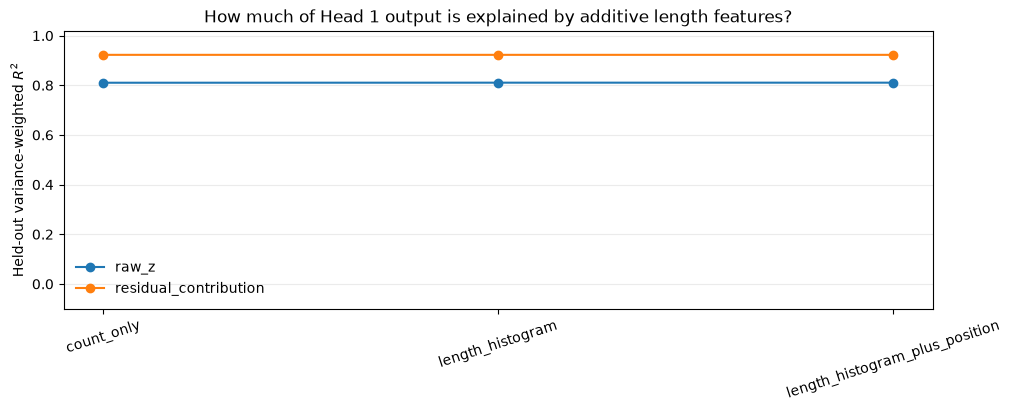

In [3]:
models = {
    'count_only': (np.c_[train_count[:, None], train_width], np.c_[eval_count[:, None], eval_width]),
    'length_histogram': (np.c_[train_hist, train_width], np.c_[eval_hist, eval_width]),
    'length_histogram_plus_position': (np.c_[train_hist, train_pos, train_width], np.c_[eval_hist, eval_pos, eval_width]),
}
def fit_score(Xtr, Xev, ytr, yev):
    fit = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(Xtr, ytr)
    pred = fit.predict(Xev)
    return {'R2': r2_score(yev, pred, multioutput='variance_weighted'), 'MSE': mean_squared_error(yev, pred), 'pred': pred, 'fit': fit}

rows = []
fits = {}
for name, (Xtr, Xev) in models.items():
    for representation, ytr, yev in [('raw_z', train_z, eval_z), ('residual_contribution', train_contrib, eval_contrib)]:
        result = fit_score(Xtr, Xev, ytr, yev); fits[(name, representation)] = result
        rows.append({'model': name, 'representation': representation, 'R2': result['R2'], 'MSE': result['MSE']})
results = pd.DataFrame(rows)
display(results.round(4))
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
for rep, group in results.groupby('representation'):
    ax.plot(group['model'], group['R2'], marker='o', label=rep)
ax.set_ylabel('Held-out variance-weighted $R^2$'); ax.set_ylim(-0.1, 1.02); ax.set_title('How much of Head 1 output is explained by additive length features?'); ax.grid(axis='y', alpha=.25); ax.legend(frameon=False); plt.xticks(rotation=18); plt.show()

## Interpretation and a local increment check

The accumulator test is sequence-level: a high score means that the output at each position can be reconstructed from the token lengths accumulated since the preceding newline. It does not prove that the attention value path itself performs the sum. The increment check below asks whether changes in Head 1's output between consecutive ordinary tokens are systematically related to the newly consumed token length.

Held-out adjacent-output increment R2 from new token length: 0.5965818855738886
Mean output-increment norm by token length:


norm              
          mean     std count
length                      
1       0.1315  0.1315  4287
2       0.2174  0.1369  4242
3       0.3366  0.1433  4221
4       0.4533  0.1719  4260
5       0.5736  0.1896  4259
6       0.6891  0.2316  4189
7       0.8081  0.2579  4229
8       0.9207  0.2799  4120

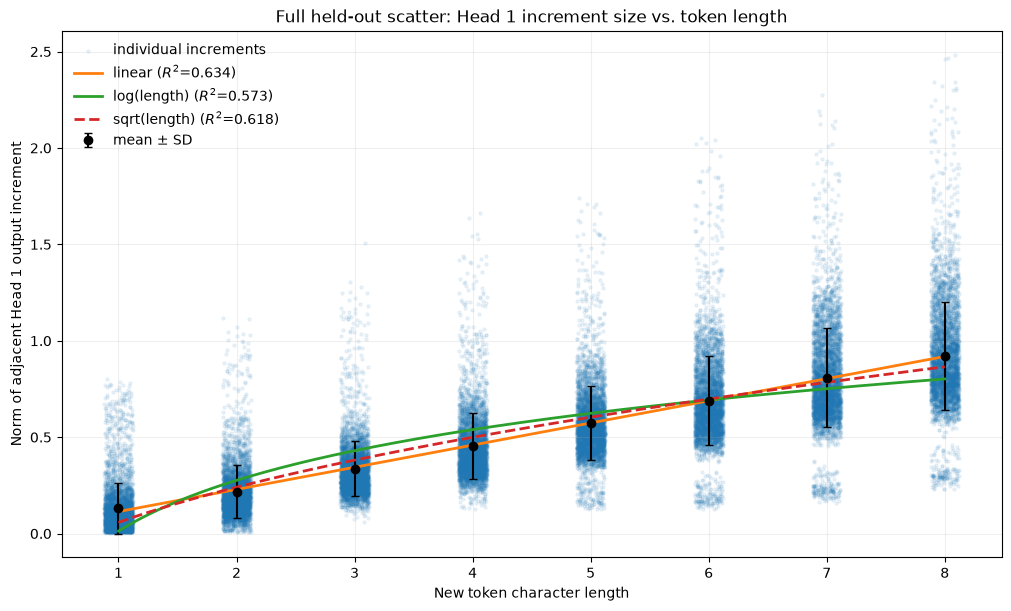

Norm-vs-length fit R2: linear=0.6338, log=0.5734, sqrt=0.6176


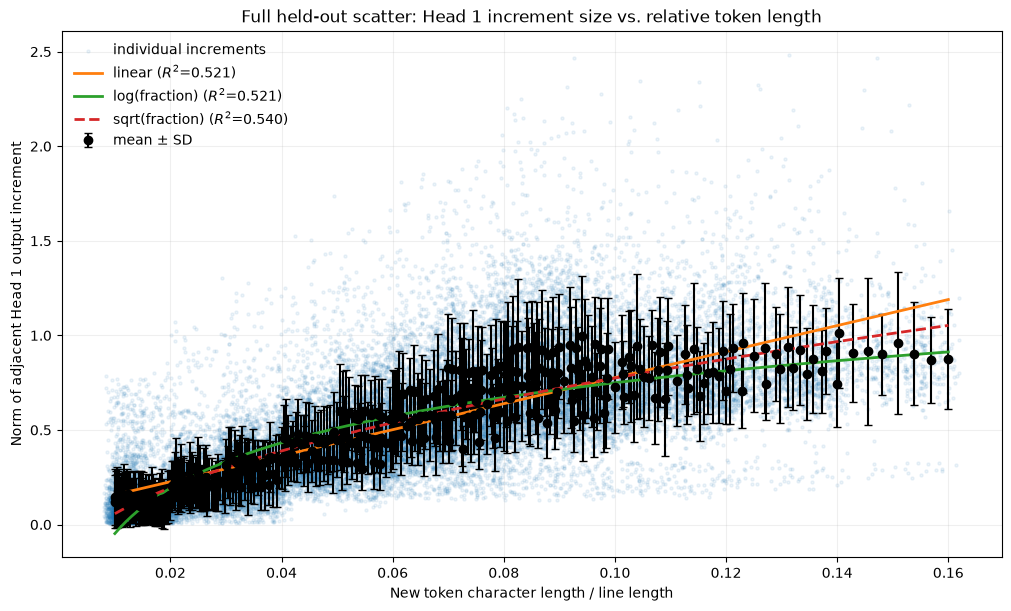

Norm-vs-length/line-length fit R2: linear=0.5207, log=0.5215, sqrt=0.5401


In [4]:
# Compare predicted and observed within-segment output increments on held-out data.
delta_z = []; delta_count = []; delta_length = []; delta_line_length = []
# Reconstruct sequence boundaries from a fresh evaluation batch so that the
# increment statistic uses adjacent positions from the same sequence.
batch = data.make_batch(N_EVAL, vocab, cfg['task'], device, 12002)
tokens = batch.tokens.detach().cpu().numpy()
line_lengths = batch.line_lengths.detach().cpu().numpy()
with torch.no_grad():
    _, cache = model.run_with_cache(batch.tokens, prepend_bos=False, names_filter=[Z_SITE])
z_all = cache[Z_SITE][:, :, HEAD].detach().cpu().numpy()
for b, row in enumerate(tokens):
    previous_q = None
    for q, token_id in enumerate(row):
        name = vocab.decode_token(int(token_id))
        if name in {'BOS', '_NEWLINE_'}:
            previous_q = None; continue
        if previous_q is not None:
            delta_z.append(z_all[b, q] - z_all[b, previous_q])
            delta_count.append(data.extract_character_count(name))
            delta_length.append(data.extract_character_count(name))
            delta_line_length.append(float(line_lengths[b]))
        previous_q = q
delta_z = np.asarray(delta_z); delta_length = np.asarray(delta_length); delta_line_length = np.asarray(delta_line_length)
increment_fit = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(delta_length[:, None], delta_z)
increment_pred = increment_fit.predict(delta_length[:, None])
print('Held-out adjacent-output increment R2 from new token length:', r2_score(delta_z, increment_pred, multioutput='variance_weighted'))
print('Mean output-increment norm by token length:')
increment_norm = np.linalg.norm(delta_z, axis=1)
increment_summary = pd.DataFrame({'length': delta_length.tolist(), 'norm': increment_norm}).groupby('length').agg(['mean','std','count']).round(4)
display(increment_summary)

# Show the complete held-out scatter, rather than only the mean by token length.
# The x-axis is discrete, so the small horizontal jitter is only for visibility;
# all fits below use the unjittered lengths.
def fit_and_r2(x, y, transform):
    basis = transform(x)
    coef = np.polyfit(basis, y, 1)
    pred = np.polyval(coef, basis)
    return coef, 1 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2)

linear_coef, linear_r2 = fit_and_r2(delta_length.astype(float), increment_norm, lambda x: x)
log_coef, log_r2 = fit_and_r2(delta_length.astype(float), increment_norm, np.log)
sqrt_coef, sqrt_r2 = fit_and_r2(delta_length.astype(float), increment_norm, np.sqrt)
x_grid = np.linspace(1, MAX_LENGTH, 300)
linear_curve = np.polyval(linear_coef, x_grid)
log_curve = np.polyval(log_coef, np.log(x_grid))
sqrt_curve = np.polyval(sqrt_coef, np.sqrt(x_grid))

rng = np.random.default_rng(12012)
jittered_x = delta_length + rng.uniform(-0.12, 0.12, size=len(delta_length))
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
ax.scatter(jittered_x, increment_norm, s=5, alpha=0.08, color='tab:blue', rasterized=True, label='individual increments')
summary = pd.DataFrame({'length': delta_length, 'norm': increment_norm}).groupby('length')['norm'].agg(['mean', 'std', 'count'])
ax.errorbar(summary.index, summary['mean'], yerr=summary['std'], fmt='o', color='black', capsize=3, label='mean $\pm$ SD')
ax.plot(x_grid, linear_curve, color='tab:orange', lw=2, label=f'linear ($R^2$={linear_r2:.3f})')
ax.plot(x_grid, log_curve, color='tab:green', lw=2, label=f'log(length) ($R^2$={log_r2:.3f})')
ax.plot(x_grid, sqrt_curve, color='tab:red', lw=2, ls='--', label=f'sqrt(length) ($R^2$={sqrt_r2:.3f})')
ax.set_xlabel('New token character length')
ax.set_ylabel('Norm of adjacent Head 1 output increment')
ax.set_title('Full held-out scatter: Head 1 increment size vs. token length')
ax.set_xticks(range(1, MAX_LENGTH + 1)); ax.grid(alpha=.2); ax.legend(frameon=False)
plt.show()
print(f'Norm-vs-length fit R2: linear={linear_r2:.4f}, log={log_r2:.4f}, sqrt={sqrt_r2:.4f}')

# Repeat the visualization after normalizing token length by the sequence's
# line length. This tests whether the increment size tracks relative rather
# than absolute token size.
length_fraction = delta_length.astype(float) / delta_line_length
fraction_linear_coef, fraction_linear_r2 = fit_and_r2(length_fraction, increment_norm, lambda x: x)
fraction_log_coef, fraction_log_r2 = fit_and_r2(length_fraction, increment_norm, np.log)
fraction_sqrt_coef, fraction_sqrt_r2 = fit_and_r2(length_fraction, increment_norm, np.sqrt)
fraction_grid = np.linspace(length_fraction.min(), length_fraction.max(), 300)
fraction_linear_curve = np.polyval(fraction_linear_coef, fraction_grid)
fraction_log_curve = np.polyval(fraction_log_coef, np.log(fraction_grid))
fraction_sqrt_curve = np.polyval(fraction_sqrt_coef, np.sqrt(fraction_grid))
fraction_jitter = length_fraction + rng.uniform(-0.002, 0.002, size=len(length_fraction))
fraction_summary = pd.DataFrame({'fraction': length_fraction, 'norm': increment_norm}).groupby('fraction')['norm'].agg(['mean', 'std', 'count'])
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
ax.scatter(fraction_jitter, increment_norm, s=5, alpha=0.08, color='tab:blue', rasterized=True, label='individual increments')
ax.errorbar(fraction_summary.index, fraction_summary['mean'], yerr=fraction_summary['std'], fmt='o', color='black', capsize=3, label='mean $\pm$ SD')
ax.plot(fraction_grid, fraction_linear_curve, color='tab:orange', lw=2, label=f'linear ($R^2$={fraction_linear_r2:.3f})')
ax.plot(fraction_grid, fraction_log_curve, color='tab:green', lw=2, label=f'log(fraction) ($R^2$={fraction_log_r2:.3f})')
ax.plot(fraction_grid, fraction_sqrt_curve, color='tab:red', lw=2, ls='--', label=f'sqrt(fraction) ($R^2$={fraction_sqrt_r2:.3f})')
ax.set_xlabel('New token character length / line length')
ax.set_ylabel('Norm of adjacent Head 1 output increment')
ax.set_title('Full held-out scatter: Head 1 increment size vs. relative token length')
ax.grid(alpha=.2); ax.legend(frameon=False)
plt.show()
print(f'Norm-vs-length/line-length fit R2: linear={fraction_linear_r2:.4f}, log={fraction_log_r2:.4f}, sqrt={fraction_sqrt_r2:.4f}')